# Exploratory Data Analysis: `dataset_playstore1.csv`
**Source:** `GamesDB/gamesdb_public_dataset` on Hugging Face (676 MB Play Store CSV)

The schema of this file is not confirmed, so the notebook **discovers the columns first** and then maps them to roles
(id, category, rating, installs, price, dates ...). Any section whose role is missing is skipped automatically.

**Sections**
1. Setup and download
2. Schema discovery (columns, dtypes, row count)
3. Load (drops e-mail columns on purpose)
4. Column-role mapping
5. Profile: missing values, duplicates, uniques
6. Parsing and feature derivation
7. Game filter
8. Distributions
9. Time analysis
10. Relationships
11. Data-quality flags
12. Developers
13. Export

## 1. Setup and download

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
plt.rcParams['figure.figsize'] = (9, 4.5)

REPO_ID = 'GamesDB/gamesdb_public_dataset'
FILENAME = 'dataset_playstore1.csv'
LOCAL_PATH = FILENAME        # change if the file already lives somewhere else

LOAD_ROWS = None             # e.g. 500_000 for a fast trial run, None = everything
ANALYSE_SCOPE = 'games'      # 'games' = analyse only games, 'all' = every app

In [ ]:
# if not os.path.exists(LOCAL_PATH):
#     # pip install huggingface_hub
#     from huggingface_hub import hf_hub_download
#     LOCAL_PATH = hf_hub_download(repo_id=REPO_ID, filename=FILENAME, repo_type='dataset')
# print(LOCAL_PATH, '|', round(os.path.getsize(LOCAL_PATH) / 1e6, 1), 'MB')

## 2. Schema discovery (cheap: does not load the whole file)

In [2]:
peek = pd.read_csv(LOCAL_PATH, nrows=5)
print(len(peek.columns), 'columns')
print(list(peek.columns))
peek.T

24 columns
['App Name', 'App Id', 'Category', 'Rating', 'Rating Count', 'Installs', 'Minimum Installs', 'Maximum Installs', 'Free', 'Price', 'Currency', 'Size', 'Minimum Android', 'Developer Id', 'Developer Website', 'Developer Email', 'Released', 'Last Updated', 'Content Rating', 'Privacy Policy', 'Ad Supported', 'In App Purchases', 'Editors Choice', 'Scraped Time']


,0,1,2,3,4
App Name,Gakondo,Ampere Battery Info,Vibook,Smart City Trichy Public Service Vehicles 17UCS548,GROW.me
App Id,com.ishakwe.gakondo,com.webserveis.batteryinfo,com.doantiepvien.crm,cst.stJoseph.ug17ucs548,com.horodyski.grower
Category,Adventure,Tools,Productivity,Communication,Tools
Rating,0.0,4.4,0.0,5.0,0.0
Rating Count,0,64,0,5,0
Installs,10+,"5,000+",50+,10+,100+
Minimum Installs,10,5000,50,10,100
Maximum Installs,15,7662,58,19,478
Free,True,True,True,True,True
Price,0,0,0,0,0


In [3]:
# Row count without holding the file in memory
n_rows = 0
for chunk in pd.read_csv(LOCAL_PATH, usecols=[0], chunksize=1_000_000):
    n_rows += len(chunk)
print(f'{n_rows:,} rows')

2,312,944 rows


## 3. Load
E-mail style columns are dropped at load time (personal data you should not keep or publish).

In [4]:
header = list(pd.read_csv(LOCAL_PATH, nrows=0).columns)
PII_PATTERN = re.compile('email|e-mail', re.I)
dropped = [c for c in header if PII_PATTERN.search(c)]
keep = [c for c in header if c not in dropped]
print('Dropped on load:', dropped)

df = pd.read_csv(LOCAL_PATH, usecols=keep, nrows=LOAD_ROWS, low_memory=False)
print(f'Loaded {df.shape[0]:,} rows x {df.shape[1]} columns | '
      f'{df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory')
df.head()

Dropped on load: ['Developer Email']
Loaded 2,312,944 rows x 23 columns | 0.85 GB in memory


,App Name,App Id,Category,Rating,Rating Count,Installs,Minimum Installs,Maximum Installs,Free,Price,Currency,Size,Minimum Android,Developer Id,Developer Website,Released,Last Updated,Content Rating,Privacy Policy,Ad Supported,In App Purchases,Editors Choice,Scraped Time
0,Gakondo,com.ishakwe.gakondo,Adventure,0.0,0.0,10+,10.0,15,True,0.0,USD,10M,7.1 and up,Jean Confident Irénée NIYIZIBYOSE,https://beniyizibyose.tk/#/,"Feb 26, 2020","Feb 26, 2020",Everyone,https://beniyizibyose.tk/projects/,False,False,False,2021-06-15 20:19:35
1,Ampere Battery Info,com.webserveis.batteryinfo,Tools,4.4,64.0,"5,000+",5000.0,7662,True,0.0,USD,2.9M,5.0 and up,Webserveis,https://webserveis.netlify.app/,"May 21, 2020","May 06, 2021",Everyone,https://dev4phones.wordpress.com/licencia-de-uso/,True,False,False,2021-06-15 20:19:35
2,Vibook,com.doantiepvien.crm,Productivity,0.0,0.0,50+,50.0,58,True,0.0,USD,3.7M,4.0.3 and up,Cabin Crew,NaN,"Aug 9, 2019","Aug 19, 2019",Everyone,https://www.vietnamairlines.com/vn/en/terms-and-conditio...,False,False,False,2021-06-15 20:19:35
3,Smart City Trichy Public Service Vehicles 17UCS548,cst.stJoseph.ug17ucs548,Communication,5.0,5.0,10+,10.0,19,True,0.0,USD,1.8M,4.0.3 and up,Climate Smart Tech2,http://www.climatesmarttech.com/,"Sep 10, 2018","Oct 13, 2018",Everyone,NaN,True,False,False,2021-06-15 20:19:35
4,GROW.me,com.horodyski.grower,Tools,0.0,0.0,100+,100.0,478,True,0.0,USD,6.2M,4.1 and up,Rafal Milek-Horodyski,http://www.horodyski.com.pl,"Feb 21, 2020","Nov 12, 2018",Everyone,http://www.horodyski.com.pl,False,False,False,2021-06-15 20:19:35


## 4. Column-role mapping
Names are matched loosely (case and punctuation ignored). Edit the `COL` dict by hand if something is mapped wrongly or missed.

In [5]:
def find_col(*candidates):
    norm = {re.sub('[^a-z0-9]', '', c.lower()): c for c in df.columns}
    for cand in candidates:
        key = re.sub('[^a-z0-9]', '', cand.lower())
        if key in norm:
            return norm[key]
    return None

COL = {
    'id':           find_col('App Id', 'appId', 'package_name', 'package', 'id'),
    'name':         find_col('App Name', 'title', 'name'),
    'cat':          find_col('Category', 'genre', 'genres'),
    'rating':       find_col('Rating', 'score'),
    'rating_count': find_col('Rating Count', 'ratings', 'reviews'),
    'installs':     find_col('Installs'),
    'min_inst':     find_col('Minimum Installs'),
    'max_inst':     find_col('Maximum Installs'),
    'free':         find_col('Free'),
    'price':        find_col('Price'),
    'size':         find_col('Size'),
    'released':     find_col('Released'),
    'updated':      find_col('Last Updated'),
    'scraped':      find_col('Scraped Time'),
    'content':      find_col('Content Rating'),
    'ads':          find_col('Ad Supported', 'contains_ads'),
    'iap':          find_col('In App Purchases', 'offers_iap'),
    'editors':      find_col('Editors Choice'),
    'dev':          find_col('Developer Id', 'developer'),
}

def has(*keys):
    return all(COL.get(k) is not None for k in keys)

print('Mapped roles :', {k: v for k, v in COL.items() if v})
print('Not found    :', [k for k, v in COL.items() if v is None])
mapped = set(v for v in COL.values() if v)
print('Unmapped columns in file:', [c for c in df.columns if c not in mapped])

Mapped roles : {'id': 'App Id', 'name': 'App Name', 'cat': 'Category', 'rating': 'Rating', 'rating_count': 'Rating Count', 'installs': 'Installs', 'min_inst': 'Minimum Installs', 'max_inst': 'Maximum Installs', 'free': 'Free', 'price': 'Price', 'size': 'Size', 'released': 'Released', 'updated': 'Last Updated', 'scraped': 'Scraped Time', 'content': 'Content Rating', 'ads': 'Ad Supported', 'iap': 'In App Purchases', 'editors': 'Editors Choice', 'dev': 'Developer Id'}
Not found    : []
Unmapped columns in file: ['Currency', 'Minimum Android', 'Developer Website', 'Privacy Policy']


## 5. Profile: dtypes, missing values, duplicates

In [6]:
prof = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(dropna=True),
})
prof['example'] = [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns]
prof

,dtype,non_null,missing_pct,n_unique,example
App Name,str,2312939,0.00,2177943,Gakondo
App Id,str,2312944,0.00,2312944,com.ishakwe.gakondo
Category,str,2312944,0.00,48,Adventure
Rating,float64,2290061,0.99,42,0.0
Rating Count,float64,2290061,0.99,38482,0.0
Installs,str,2312837,0.00,22,10+
Minimum Installs,float64,2312837,0.00,22,10.0
Maximum Installs,int64,2312944,0.00,251563,15
Free,bool,2312944,0.00,2,True
Price,float64,2312944,0.00,1063,0.0


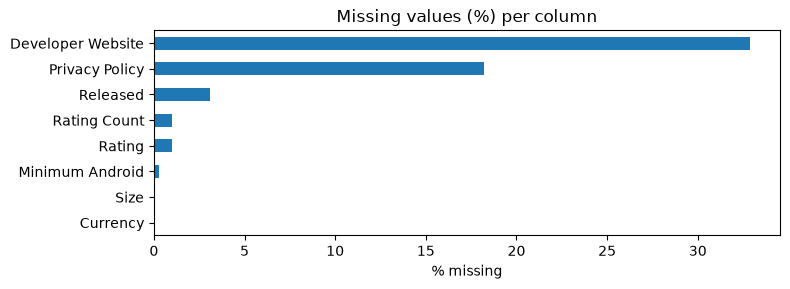

In [7]:
miss = prof['missing_pct'].sort_values()
miss = miss[miss > 0]
if len(miss):
    miss.plot.barh(figsize=(8, max(3, 0.3 * len(miss))), title='Missing values (%) per column')
    plt.xlabel('% missing'); plt.tight_layout(); plt.show()
else:
    print('No missing values at all.')

In [8]:
print('Fully duplicated rows:', f'{df.duplicated().sum():,}')
if has('id'):
    d = df[COL['id']].duplicated().sum()
    print(f"Duplicate {COL['id']}:", f'{d:,}', f'({d / len(df) * 100:.2f}%)')
    print(f"Unique {COL['id']}   :", f"{df[COL['id']].nunique():,}")

Fully duplicated rows: 0
Duplicate App Id: 0 (0.00%)
Unique App Id   : 2,312,944


In [9]:
# Numeric summary and low-cardinality categorical columns
display(df.describe().T)
for c in df.columns:
    if df[c].dtype == object and df[c].nunique() <= 30:
        print('\n---', c)
        print(df[c].value_counts(dropna=False).head(30))

,count,mean,std,min,25%,50%,75%,max
Rating,2290061.0,2.203152,2.106223e+00,0.0,0.0,2.9,4.3,5.000000e+00
Rating Count,2290061.0,2864.838877,2.121626e+05,0.0,0.0,6.0,42.0,1.385576e+08
Minimum Installs,2312837.0,183445.213958,1.513144e+07,0.0,50.0,500.0,5000.0,1.000000e+10
Maximum Installs,2312944.0,320201.713137,2.355495e+07,0.0,84.0,695.0,7354.0,1.205763e+10
Price,2312944.0,0.103499,2.633127e+00,0.0,0.0,0.0,0.0,4.000000e+02


## 6. Parsing and feature derivation
New columns are prefixed `x_` so the raw columns stay untouched. Strings such as `10,000+`, `$1.99` or `12M` are converted to numbers.

In [10]:
def numeric_from_text(s):
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return pd.to_numeric(s.astype(str).str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')

def to_dt(s):
    try:
        return pd.to_datetime(s, errors='coerce', format='mixed')
    except (TypeError, ValueError):
        return pd.to_datetime(s, errors='coerce')

def to_bool(s):
    if s.dtype == bool:
        return s
    return s.astype(str).str.strip().str.lower().map(
        {'true': True, 'false': False, '1': True, '0': False, 'yes': True, 'no': False, '1.0': True, '0.0': False})

if has('rating'):       df['x_rating'] = numeric_from_text(df[COL['rating']])
if has('rating_count'): df['x_rating_count'] = numeric_from_text(df[COL['rating_count']])
if has('installs'):     df['x_installs'] = numeric_from_text(df[COL['installs']])
if has('min_inst'):     df['x_min_inst'] = numeric_from_text(df[COL['min_inst']])
if has('max_inst'):     df['x_max_inst'] = numeric_from_text(df[COL['max_inst']])
if has('price'):        df['x_price'] = numeric_from_text(df[COL['price']])
for role in ['free', 'ads', 'iap', 'editors']:
    if has(role):       df['x_' + role] = to_bool(df[COL[role]])
for role in ['released', 'updated', 'scraped']:
    if has(role):       df['x_' + role] = to_dt(df[COL[role]])

if has('size'):
    s = df[COL['size']]
    if pd.api.types.is_numeric_dtype(s):
        df['x_size_mb'] = s.astype(float)   # unit unknown, check the histogram below
    else:
        parts = s.astype(str).str.replace(',', '', regex=False).str.extract(r'^\s*([0-9.]+)\s*([kKmMgG]?)')
        mult = parts[1].str.lower().map({'k': 1 / 1024, 'm': 1.0, 'g': 1024.0})
        df['x_size_mb'] = pd.to_numeric(parts[0], errors='coerce') * mult

# Best available "installs" number (prefer the explicit minimum)
for c in ['x_min_inst', 'x_installs']:
    if c in df.columns:
        df['x_installs_best'] = df[c]
        break

if 'x_released' in df.columns:
    ref = df['x_scraped'] if 'x_scraped' in df.columns else pd.Timestamp.today()
    df['x_age_years'] = (ref - df['x_released']).dt.days / 365.25
    df['x_release_year'] = df['x_released'].dt.year
if 'x_updated' in df.columns:
    df['x_update_year'] = df['x_updated'].dt.year

print('Derived columns:', [c for c in df.columns if c.startswith('x_')])
df[[c for c in df.columns if c.startswith('x_')]].describe(include='all').T

Derived columns: ['x_rating', 'x_rating_count', 'x_installs', 'x_min_inst', 'x_max_inst', 'x_price', 'x_free', 'x_ads', 'x_iap', 'x_editors', 'x_released', 'x_updated', 'x_scraped', 'x_size_mb', 'x_installs_best', 'x_age_years', 'x_release_year', 'x_update_year']


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
x_rating,2290061.0,NaN,NaN,NaN,2.203152,0.0,0.0,2.9,4.3,5.0,2.106223
x_rating_count,2290061.0,NaN,NaN,NaN,2864.838877,0.0,0.0,6.0,42.0,138557570.0,212162.571037
x_installs,2312837.0,NaN,NaN,NaN,183445.213958,0.0,50.0,500.0,5000.0,10000000000.0,15131439.059694
x_min_inst,2312837.0,NaN,NaN,NaN,183445.213958,0.0,50.0,500.0,5000.0,10000000000.0,15131439.059694
x_max_inst,2312944.0,NaN,NaN,NaN,320201.713137,0.0,84.0,695.0,7354.0,12057627016.0,23554954.886548
x_price,2312944.0,NaN,NaN,NaN,0.103499,0.0,0.0,0.0,0.0,400.0,2.633127
x_free,2312944,2,True,2267876,NaN,NaN,NaN,NaN,NaN,NaN,NaN
x_ads,2312944,2,False,1162170,NaN,NaN,NaN,NaN,NaN,NaN,NaN
x_iap,2312944,2,False,2117635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
x_editors,2312944,2,False,2312091,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Game filter
Check the category list first; the file may use names like `Action` or `GAME_ACTION`. Edit `GAME_CATS` if needed.

In [11]:
if has('cat'):
    cats = df[COL['cat']].value_counts(dropna=False)
    print(len(cats), 'distinct categories')
    display(cats.head(70))

48 distinct categories


Category
Education                  241090
Music & Audio              154906
Tools                      143988
Business                   143771
Entertainment              138276
Lifestyle                  118331
Books & Reference          116728
Personalization             89210
Health & Fitness            83510
Productivity                79698
Shopping                    75256
Food & Drink                73927
Travel & Local              67288
Finance                     65466
Arcade                      53792
Puzzle                      51168
Casual                      50813
Communication               48167
Sports                      47483
Social                      44734
News & Magazines            42807
Photography                 35552
Medical                     32065
Action                      27555
Maps & Navigation           26722
Simulation                  23282
Adventure                   23203
Educational                 21308
Art & Design                18539
Auto 

In [12]:
GAME_CATS = {'action', 'adventure', 'arcade', 'board', 'card', 'casino', 'casual', 'educational',
             'music', 'puzzle', 'racing', 'role playing', 'simulation', 'sports', 'strategy', 'trivia', 'word'}

if 'is_game' in [c.lower() for c in df.columns]:
    gcol = [c for c in df.columns if c.lower() == 'is_game'][0]
    df['x_is_game'] = to_bool(df[gcol])
    print('Used existing is_game column')
elif has('cat'):
    key = df[COL['cat']].astype(str).str.lower().str.replace('_', ' ', regex=False).str.strip()
    df['x_is_game'] = key.isin(GAME_CATS) | key.str.startswith('game')
else:
    df['x_is_game'] = False

n_games = int(df['x_is_game'].sum())
print(f'Games: {n_games:,} of {len(df):,} ({n_games / len(df) * 100:.1f}%)')

if ANALYSE_SCOPE == 'games' and n_games > 0:
    A = df[df['x_is_game']].copy()
    print('Analysing GAMES only ->', f'{len(A):,} rows')
else:
    A = df
    print('Analysing ALL apps ->', f'{len(A):,} rows (no games detected or scope = all)')

Games: 375,996 of 2,312,944 (16.3%)
Analysing GAMES only -> 375,996 rows


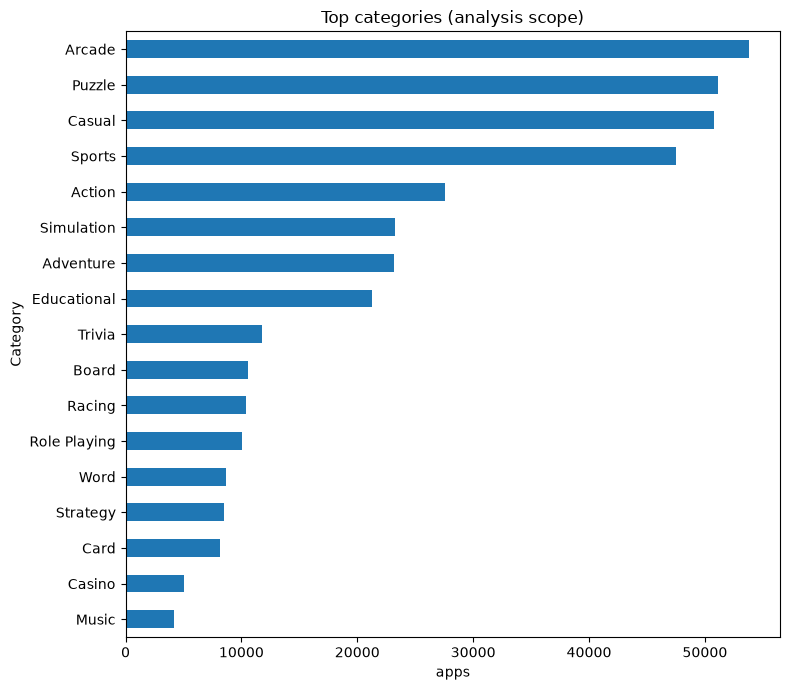

In [13]:
if has('cat'):
    A[COL['cat']].value_counts().head(25).sort_values().plot.barh(figsize=(8, 7), title='Top categories (analysis scope)')
    plt.xlabel('apps'); plt.tight_layout(); plt.show()

## 8. Distributions

rating == 0 : 130,286 | NaN : 7,361


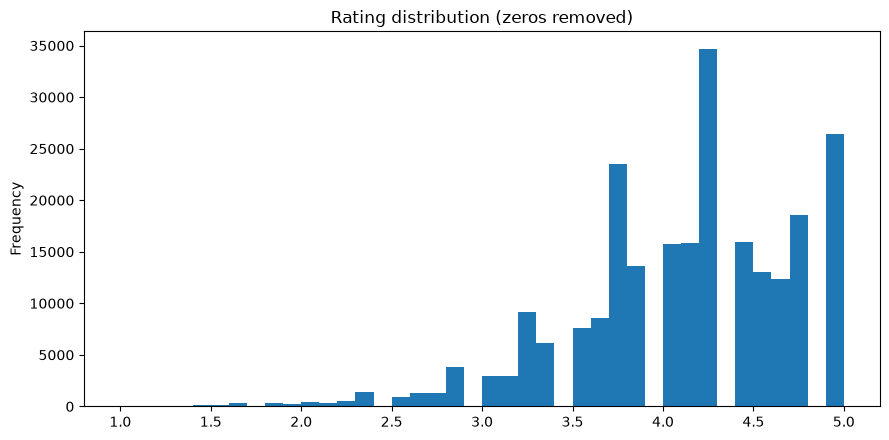

count    238349.000000
mean          4.094661
std           0.618837
min           1.000000
25%           3.800000
50%           4.200000
75%           4.500000
max           5.000000
Name: x_rating, dtype: float64


In [14]:
def hist(series, title, bins=50, log_y=False, clip=None):
    s = series.dropna()
    if clip: s = s[(s >= clip[0]) & (s <= clip[1])]
    if s.empty:
        print('skip (empty):', title); return
    s.plot.hist(bins=bins, title=title, logy=log_y)
    plt.tight_layout(); plt.show()

if 'x_rating' in A:
    r = A['x_rating']
    print('rating == 0 :', f'{(r == 0).sum():,}', '| NaN :', f'{r.isna().sum():,}')
    hist(r[r > 0], 'Rating distribution (zeros removed)', bins=40)
    print(r[r > 0].describe())

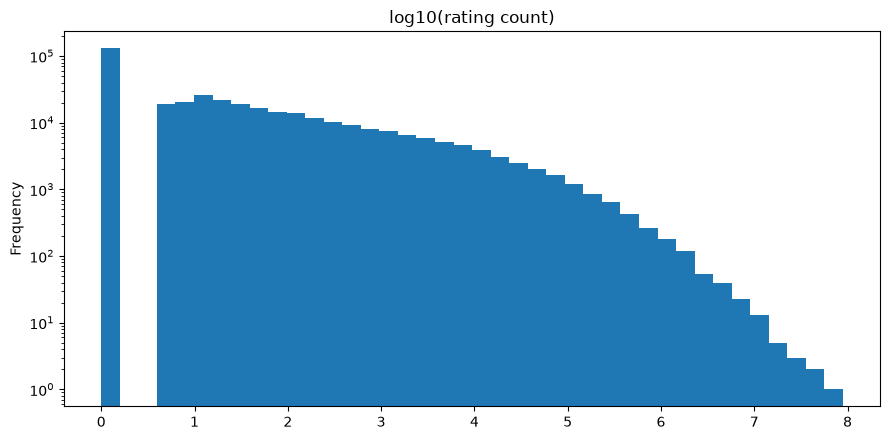

count    3.686350e+05
mean     7.634990e+03
std      2.445363e+05
min      0.000000e+00
50%      1.200000e+01
90%      1.753000e+03
99%      9.793100e+04
max      8.917710e+07
Name: x_rating_count, dtype: float64


In [15]:
if 'x_rating_count' in A:
    hist(np.log10(A['x_rating_count'].clip(lower=1)), 'log10(rating count)', bins=40, log_y=True)
    print(A['x_rating_count'].describe(percentiles=[.5, .9, .99]))

x_installs_best
0.000000e+00     1135
1.000000e+00     8934
5.000000e+00    11481
1.000000e+01    47743
5.000000e+01    24848
1.000000e+02    60701
5.000000e+02    25421
1.000000e+03    57488
5.000000e+03    22403
1.000000e+04    44043
5.000000e+04    15146
1.000000e+05    27747
5.000000e+05     8979
1.000000e+06    13132
5.000000e+06     3013
1.000000e+07     3047
5.000000e+07      410
1.000000e+08      225
5.000000e+08       13
1.000000e+09        2
Name: count, dtype: int64


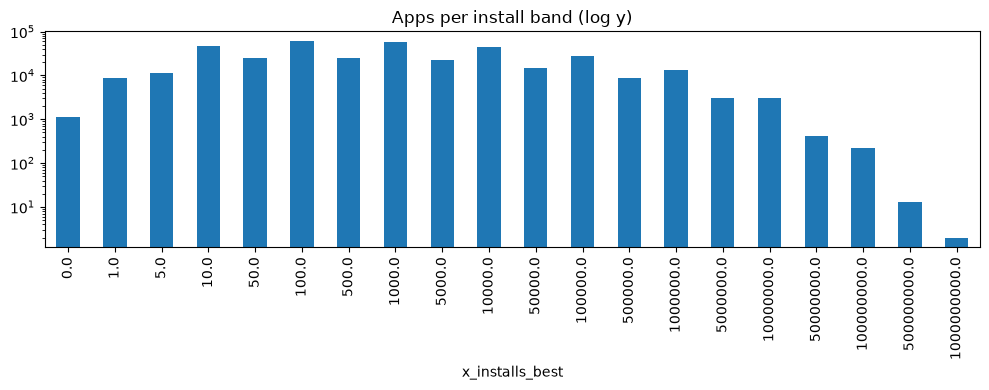

In [16]:
if 'x_installs_best' in A:
    vc = A['x_installs_best'].value_counts().sort_index()
    print(vc.head(30))
    vc.plot.bar(logy=True, title='Apps per install band (log y)', figsize=(10, 4))
    plt.tight_layout(); plt.show()

Paid apps: 9,867 (2.62%)


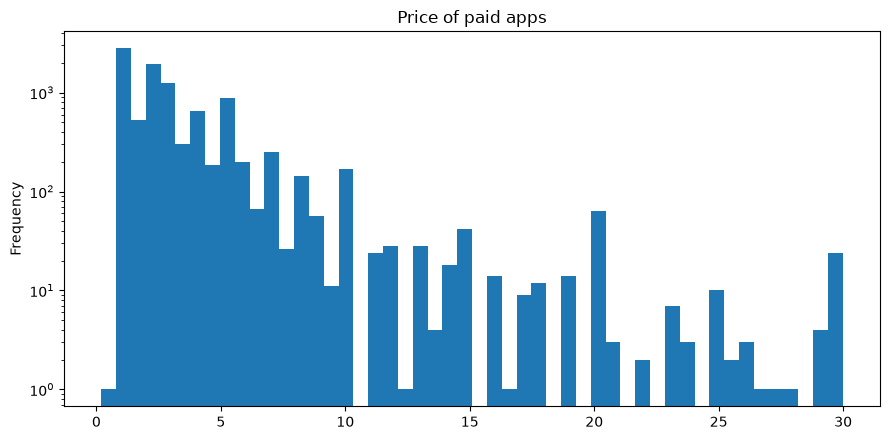

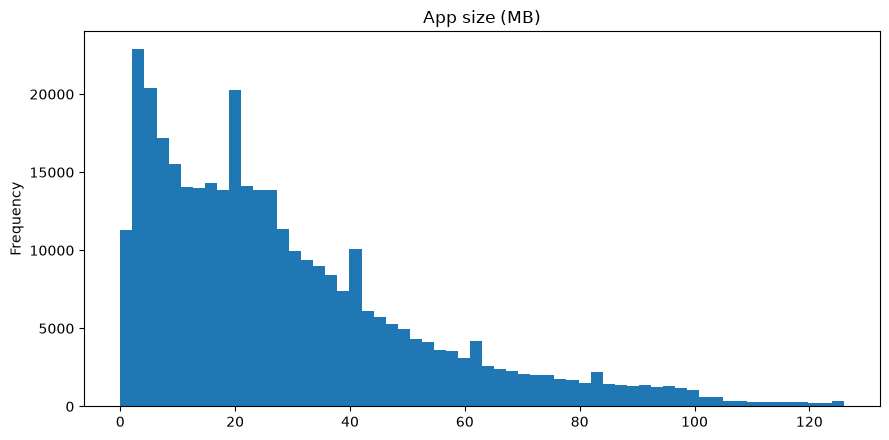

count    354277.000000
mean         30.290410
std          29.023739
min           0.009766
25%          11.000000
50%          23.000000
75%          41.000000
max        1536.000000
Name: x_size_mb, dtype: float64


In [17]:
if 'x_price' in A:
    paid = A[A['x_price'] > 0]
    print(f"Paid apps: {len(paid):,} ({len(paid) / len(A) * 100:.2f}%)")
    hist(paid['x_price'], 'Price of paid apps', bins=50, log_y=True, clip=(0, paid['x_price'].quantile(0.99)))
if 'x_size_mb' in A:
    hist(A['x_size_mb'], 'App size (MB)', bins=60, clip=(0, A['x_size_mb'].quantile(0.99)))
    print(A['x_size_mb'].describe())

In [18]:
for role, title in [('free', 'Free vs paid'), ('ads', 'Ad supported'), ('iap', 'In-app purchases'),
                    ('editors', "Editor's choice"), ('content', 'Content rating')]:
    col = 'x_' + role if ('x_' + role) in A.columns else COL.get(role)
    if col is None or col not in A.columns:
        continue
    vc = A[col].value_counts(dropna=False, normalize=True).mul(100).round(2)
    print(f'\n{title}\n', vc.head(10))


Free vs paid
 x_free
True     97.35
False     2.65
Name: proportion, dtype: float64

Ad supported
 x_ads
True     74.18
False    25.82
Name: proportion, dtype: float64

In-app purchases
 x_iap
False    76.69
True     23.31
Name: proportion, dtype: float64

Editor's choice
 x_editors
False    99.86
True      0.14
Name: proportion, dtype: float64

Content rating
 Content Rating
Everyone           81.78
Teen               11.99
Everyone 10+        4.38
Mature 17+          1.82
Adults only 18+     0.01
Unrated             0.01
Name: proportion, dtype: float64


In [21]:
# Monetisation by category (games scope): share with ads / IAP / paid
if has('cat'):
    g = A.groupby(COL['cat'])
    out = pd.DataFrame({'apps': g.size()})
    if 'x_ads' in A:   out['ads_%'] = (g['x_ads'].mean() * 100).round(1)
    if 'x_iap' in A:   out['iap_%'] = (g['x_iap'].mean() * 100).round(1)
    if 'x_price' in A: out['paid_%'] = (g['x_price'].apply(lambda s: (s > 0).mean()) * 100).round(1)
    if 'x_rating' in A: out['median_rating'] = g['x_rating'].apply(lambda s: s[s > 0].median()).round(2)
    out.sort_values('apps', ascending=False).head(25)

## 9. Time analysis

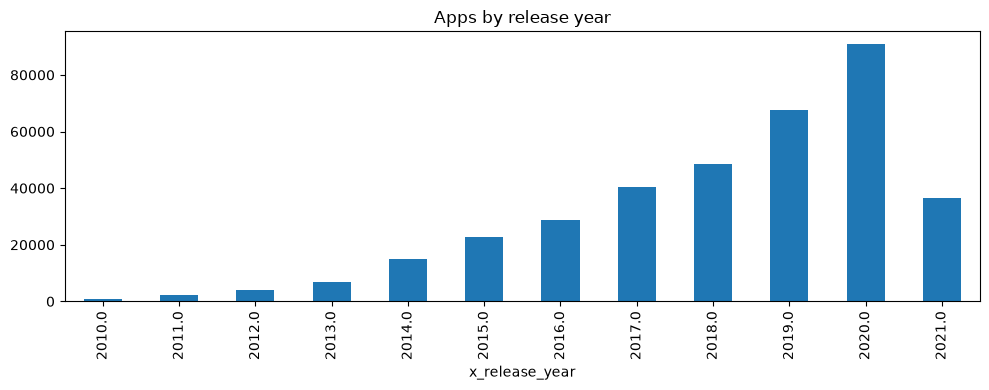

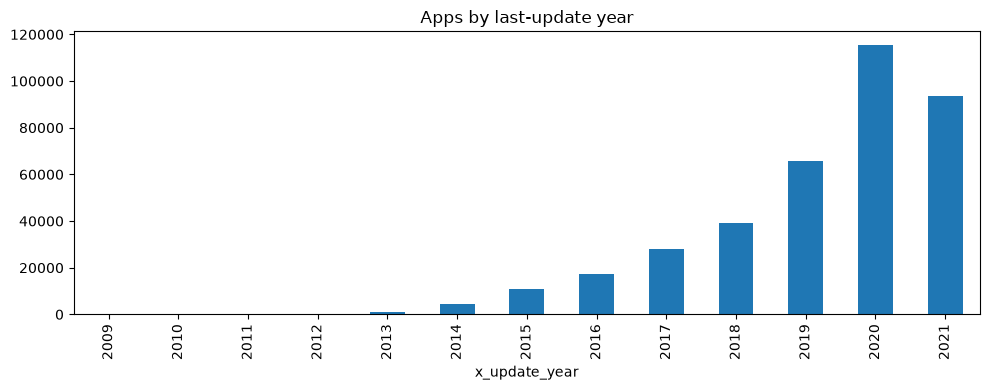

Scrape window: 2021-06-15 20:19:35 -> 2021-06-16 15:10:42


In [23]:
if 'x_release_year' in A:
    ry = A['x_release_year'].value_counts().sort_index()
    ry = ry[(ry.index >= 2008) & (ry.index <= pd.Timestamp.today().year)]
    ry.plot.bar(title='Apps by release year', figsize=(10, 4)); plt.tight_layout(); plt.show()
if 'x_update_year' in A:
    uy = A['x_update_year'].value_counts().sort_index()
    uy = uy[(uy.index >= 2008) & (uy.index <= pd.Timestamp.today().year)]
    uy.plot.bar(title='Apps by last-update year', figsize=(10, 4)); plt.tight_layout(); plt.show()
if 'x_scraped' in df:
    print('Scrape window:', df['x_scraped'].min(), '->', df['x_scraped'].max())

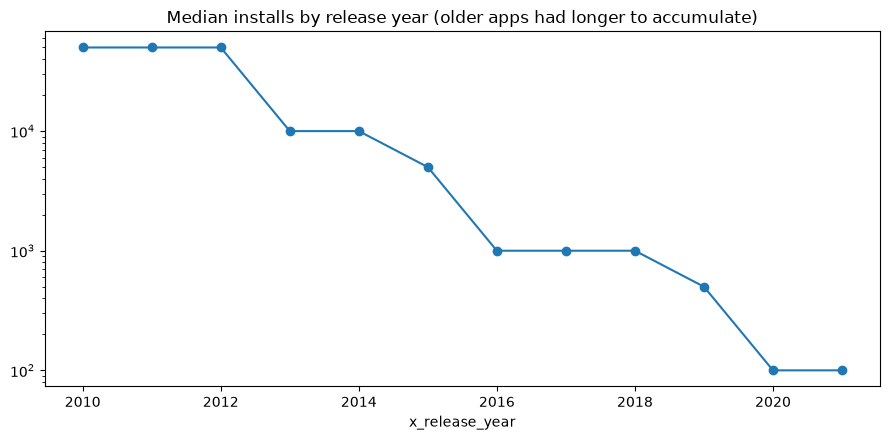

In [24]:
if 'x_release_year' in A and 'x_installs_best' in A:
    t = A.groupby('x_release_year')['x_installs_best'].median()
    t = t[(t.index >= 2010)]
    t.plot(marker='o', logy=True, title='Median installs by release year (older apps had longer to accumulate)')
    plt.tight_layout(); plt.show()

## 10. Relationships

Spearman correlation (rating_count, installs, price are log1p)


,rating,rating_count,installs,price,size_mb,age_years
rating,1.00,-0.18,-0.37,0.02,-0.06,-0.12
rating_count,-0.18,1.00,0.87,0.03,0.23,0.32
installs,-0.37,0.87,1.00,-0.02,0.23,0.32
price,0.02,0.03,-0.02,1.00,0.01,0.12
size_mb,-0.06,0.23,0.23,0.01,1.00,-0.19
age_years,-0.12,0.32,0.32,0.12,-0.19,1.00


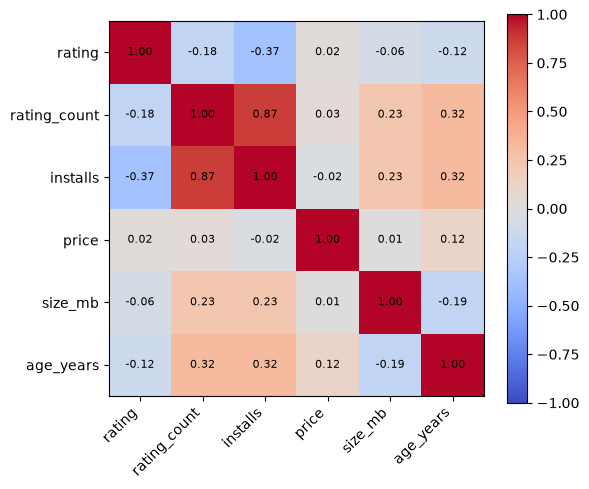

In [25]:
num = pd.DataFrame(index=A.index)
for src, name in [('x_rating', 'rating'), ('x_rating_count', 'rating_count'), ('x_installs_best', 'installs'),
                  ('x_price', 'price'), ('x_size_mb', 'size_mb'), ('x_age_years', 'age_years')]:
    if src in A:
        num[name] = A[src]
for c in ['rating_count', 'installs', 'price']:
    if c in num:
        num[c] = np.log1p(num[c])
if 'rating' in num:
    num.loc[num['rating'] <= 0, 'rating'] = np.nan

sample = num.sample(min(len(num), 500_000), random_state=0)
corr = sample.corr(method='spearman')
print('Spearman correlation (rating_count, installs, price are log1p)')
display(corr.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()

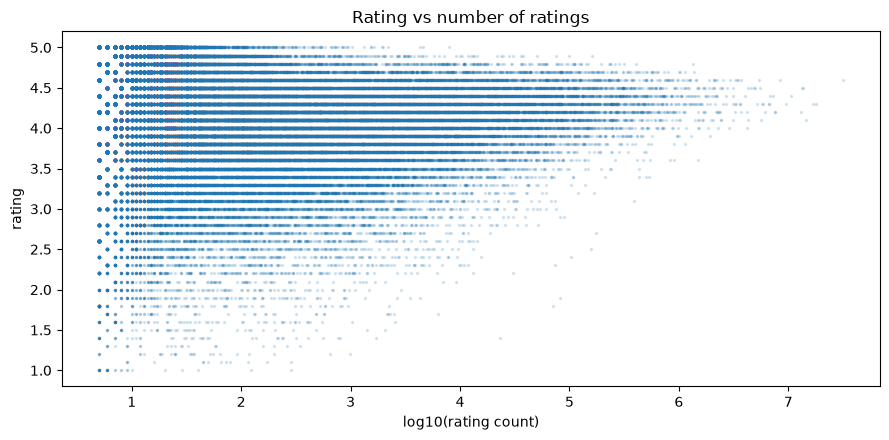

Ratings from few voters are noisy: consider a minimum rating-count threshold before using rating as a target.


In [26]:
if 'x_rating' in A and 'x_rating_count' in A:
    s = A[(A['x_rating'] > 0) & (A['x_rating_count'] > 0)].sample(min(100_000, len(A)), random_state=0)
    plt.scatter(np.log10(s['x_rating_count']), s['x_rating'], s=2, alpha=0.15)
    plt.xlabel('log10(rating count)'); plt.ylabel('rating'); plt.title('Rating vs number of ratings')
    plt.tight_layout(); plt.show()
    print('Ratings from few voters are noisy: consider a minimum rating-count threshold before using rating as a target.')

In [27]:
if 'x_price' in A and 'x_rating' in A:
    grp = np.where(A['x_price'] > 0, 'paid', 'free')
    print(A[A['x_rating'] > 0].groupby(grp[A['x_rating'] > 0])['x_rating'].describe().round(2))

         count  mean   std  min  25%  50%  75%  max
free  231437.0  4.09  0.62  1.0  3.8  4.2  4.5  5.0
paid    6912.0  4.15  0.56  1.0  3.9  4.2  4.5  5.0


## 11. Data-quality flags

In [28]:
flags = {}
if 'x_rating' in df:
    flags['rating outside 0..5'] = ((df['x_rating'] < 0) | (df['x_rating'] > 5)).sum()
    if 'x_rating_count' in df:
        flags['rating == 0 but has rating_count > 0'] = ((df['x_rating'] == 0) & (df['x_rating_count'] > 0)).sum()
        flags['rating > 0 but rating_count == 0'] = ((df['x_rating'] > 0) & (df['x_rating_count'] == 0)).sum()
if 'x_min_inst' in df and 'x_max_inst' in df:
    flags['min_installs > max_installs'] = (df['x_min_inst'] > df['x_max_inst']).sum()
if 'x_rating_count' in df and 'x_max_inst' in df:
    flags['rating_count > max_installs'] = (df['x_rating_count'] > df['x_max_inst']).sum()
if 'x_free' in df and 'x_price' in df:
    flags['free == True but price > 0'] = ((df['x_free'] == True) & (df['x_price'] > 0)).sum()
    flags['free == False but price == 0'] = ((df['x_free'] == False) & (df['x_price'] == 0)).sum()
if 'x_released' in df:
    flags['released in the future'] = (df['x_released'] > pd.Timestamp.today()).sum()
    flags['released date unparseable / missing'] = df['x_released'].isna().sum()
if 'x_released' in df and 'x_updated' in df:
    flags['last_updated before released'] = (df['x_updated'] < df['x_released']).sum()
if 'x_size_mb' in df:
    flags['size missing / unparseable'] = df['x_size_mb'].isna().sum()
    flags['size > 4 GB'] = (df['x_size_mb'] > 4096).sum()
if has('id'):
    flags['duplicate app id'] = df[COL['id']].duplicated().sum()

qa = pd.Series(flags, name='rows').astype(int).to_frame()
qa['% of rows'] = (qa['rows'] / len(df) * 100).round(3)
qa

,rows,% of rows
rating outside 0..5,0,0.000
rating == 0 but has rating_count > 0,0,0.000
rating > 0 but rating_count == 0,0,0.000
min_installs > max_installs,0,0.000
rating_count > max_installs,489,0.021
free == True but price > 0,0,0.000
free == False but price == 0,135,0.006
released in the future,0,0.000
released date unparseable / missing,71053,3.072
last_updated before released,9881,0.427


## 12. Developers

Distinct developers: 156,693
Developers with 1 app: 65.5%


Developer Id
Skalpelis                           1333
Games2Jolly                          977
Gallus Golf                          618
kicker - Amateurfußball              526
JRK Games                            470
Game Changers LT                     425
Exposure Events, LLC                 411
Kavi Games                           380
Best Escape Games Studio             349
Enterprise Digital Solutions srl     328
MATCHPOINT                           306
vmapit.de                            280
Andreas Gigli                        278
PLAYTOUCH                            276
FanChants.com                        255
Sifo-Dyas                            225
galaticdroids                        221
VascoGames                           219
Tapps Games                          217
Chronogolf, Inc.                     207
Name: count, dtype: int64

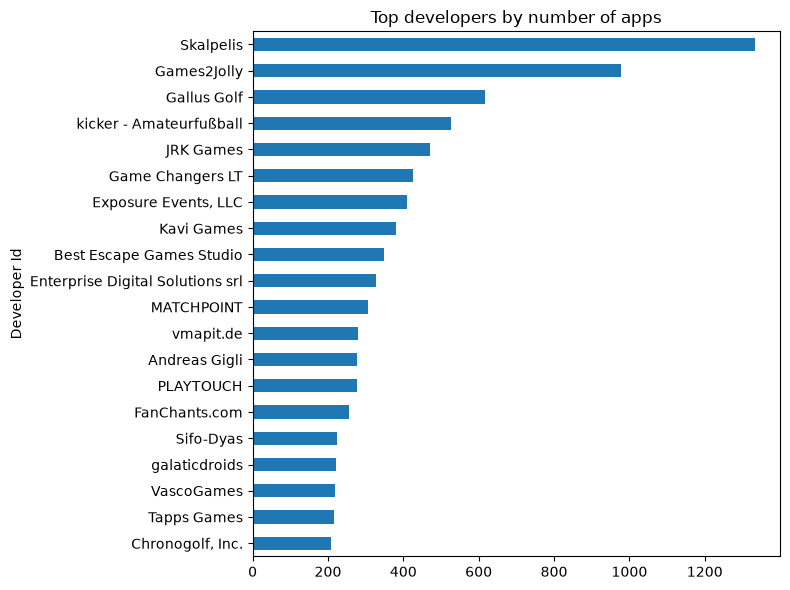

In [29]:
if has('dev'):
    dv = A[COL['dev']].value_counts()
    print('Distinct developers:', f'{len(dv):,}')
    print('Developers with 1 app:', f'{(dv == 1).mean() * 100:.1f}%')
    display(dv.head(20))
    dv.head(20).sort_values().plot.barh(figsize=(8, 6), title='Top developers by number of apps')
    plt.tight_layout(); plt.show()
else:
    print('No developer column found.')

## 13. Export
Saves the analysis frame and a column report, so you do not need to reload the 676 MB CSV each time.

In [30]:
out_cols = [c for c in A.columns]
try:
    A[out_cols].to_parquet('playstore_analysis_frame.parquet', index=False)   # needs pyarrow
    print('Saved playstore_analysis_frame.parquet')
except Exception as e:
    print('Parquet failed (', type(e).__name__, ') -> saving CSV instead')
    A[out_cols].to_csv('playstore_analysis_frame.csv', index=False)

prof.to_csv('playstore_column_report.csv')
print('Saved playstore_column_report.csv')

Saved playstore_analysis_frame.parquet
Saved playstore_column_report.csv


### Things to look at once it runs
- **Section 2/4:** the real column list and which roles were mapped. Paste it back if anything is wrong.
- **Section 7:** the category list, to confirm the game filter catches the right rows.
- **Section 11:** how much of the data is inconsistent before you build anything on it.
- **Section 9:** the scrape window, which you need for citing the dataset.